# Correlation and Covariance: Python Examples

Explore covariance, Pearson/Spearman/Kendall correlation, scatter plots, and correlation matrices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)
print('NumPy:', np.__version__)
print('pandas:', pd.__version__)


NumPy: 2.3.5
pandas: 2.2.3


## 1. Covariance and Pearson correlation

In [2]:
hours = np.array([1, 2, 3, 4, 5, 6], dtype=float)
scores = np.array([52, 55, 61, 64, 70, 74], dtype=float)
print('Sample covariance:', np.cov(hours, scores, ddof=1)[0, 1])
r, p = stats.pearsonr(hours, scores)
print('Pearson r:', round(float(r), 4))
print('p-value:', round(float(p), 4))


Sample covariance: 15.8
Pearson r: 0.9962
p-value: 0.0


## 2. Compare correlation methods

In [3]:
print('Pearson:', stats.pearsonr(hours, scores))
print('Spearman:', stats.spearmanr(hours, scores))
print('Kendall:', stats.kendalltau(hours, scores))


Pearson: PearsonRResult(statistic=np.float64(0.9962293075839316), pvalue=np.float64(2.130037586382071e-05))
Spearman: SignificanceResult(statistic=np.float64(1.0), pvalue=np.float64(0.0))
Kendall: SignificanceResult(statistic=np.float64(0.9999999999999999), pvalue=np.float64(0.002777777777777778))


## 3. Scatter plot and least-squares line

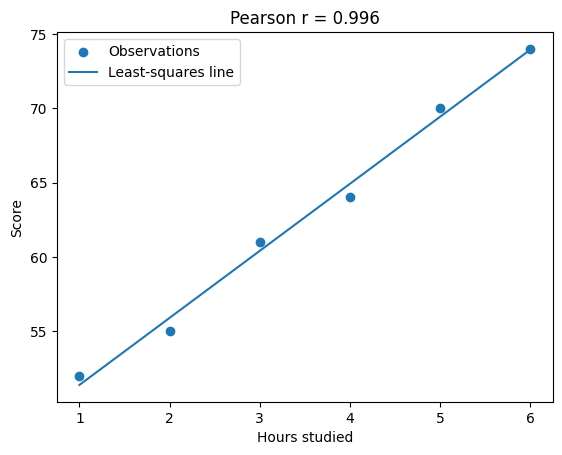

In [4]:
slope, intercept, r_value, p_value, std_err = stats.linregress(hours, scores)
plt.scatter(hours, scores, label='Observations')
plt.plot(hours, intercept + slope*hours, label='Least-squares line')
plt.xlabel('Hours studied')
plt.ylabel('Score')
plt.title(f'Pearson r = {r_value:.3f}')
plt.legend()
plt.show()


## 4. A nonlinear U-shaped relationship

Pearson correlation for U-shaped data: 1.6693666856534284e-16


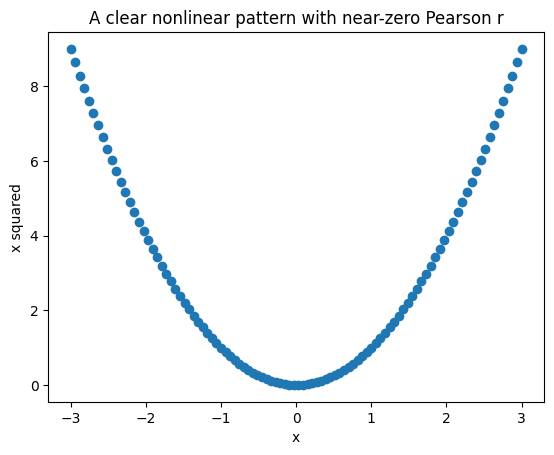

In [5]:
x = np.linspace(-3, 3, 100)
y = x**2
print('Pearson correlation for U-shaped data:', np.corrcoef(x, y)[0, 1])
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('x squared')
plt.title('A clear nonlinear pattern with near-zero Pearson r')
plt.show()


## 5. Outlier sensitivity

In [6]:
x = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y = np.array([2, 4, 5, 4, 6, 7], dtype=float)
y_outlier = np.append(y, 25)
x_outlier = np.append(x, 7)
print('Pearson without added point:', np.corrcoef(x, y)[0, 1])
print('Pearson with added point:', np.corrcoef(x_outlier, y_outlier)[0, 1])
print('Spearman with added point:', stats.spearmanr(x_outlier, y_outlier).statistic)


Pearson without added point: 0.9157015435010396
Pearson with added point: 0.746967077272214
Spearman with added point: 0.9369749612033814


## 6. Correlation matrix with pandas

In [7]:
df = pd.DataFrame({
    'study_hours': [1, 2, 3, 4, 5, 6],
    'score': [52, 55, 61, 64, 70, 74],
    'sleep_hours': [8, 7, 7, 6, 7, 6]
})
print(df.cov(numeric_only=True))
print(df.corr(numeric_only=True))


             study_hours      score  sleep_hours
study_hours          3.5  15.800000    -1.100000
score               15.8  71.866667    -4.666667
sleep_hours         -1.1  -4.666667     0.566667
             study_hours     score  sleep_hours
study_hours     1.000000  0.996229    -0.781079
score           0.996229  1.000000    -0.731272
sleep_hours    -0.781079 -0.731272     1.000000


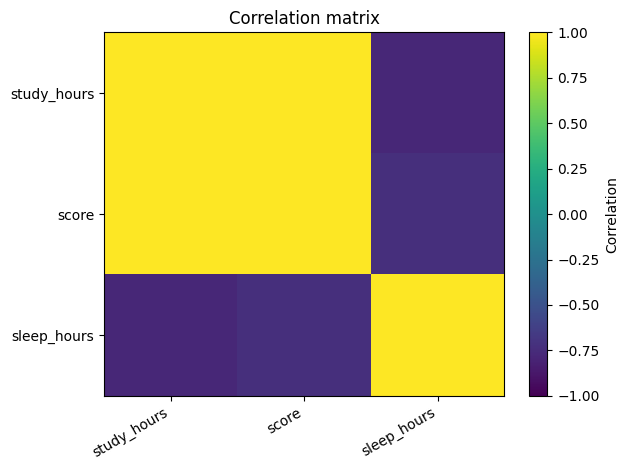

In [8]:
corr = df.corr(numeric_only=True)
plt.imshow(corr, vmin=-1, vmax=1, aspect='auto')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=30, ha='right')
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(label='Correlation')
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()


## Key takeaways

- Covariance depends on units; correlation is standardized and unitless.
- Pearson describes linear association, while rank-based methods describe monotonic rank association.
- Visualize relationships and investigate outliers before interpreting coefficients.
- Correlation alone cannot establish causation.